# 04. Evaluation, Benchmarking & Stakeholder Validation

**Lead Responsible**: Weerasooriya W.H.M.S.P (`IT24104192`)  
**Module**: IT3091 – Machine Learning | Group 2026-AI-15  
**Track**: Industry Explorer Track  

---

## Objectives
1. Synthesize and evaluate top association rules using Support, Confidence, Lift (> 1.0), and Conviction.
2. Compare supervised classification algorithms (Logistic Regression vs. Decision Tree vs. Random Forest).
3. Cross-validate findings against the Sri Lankan POS reference dataset for staple FMCG goods (tea, dairy, biscuits).
4. Align insights with the independent supermarket owner's qualitative feedback and compile actionable store layout and restocking recommendations.

In [2]:
import sys
import time
from pathlib import Path

# Resolve project root dynamically
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

# Scikit-learn Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    average_precision_score,
    roc_curve, 
    precision_recall_curve, 
    confusion_matrix
)

# Project modular imports
from src.utils import setup_plot_style, save_figure, export_summary_table

setup_plot_style()
print(f"[OK] Python Interpreter : {sys.executable}")
print(f"[OK] Project Root       : {PROJECT_ROOT}")

[OK] Python Interpreter : E:\SLIIT\Y3S1\IT3091 - Machine Learning\Assignments\SuperMarket\supermarket-basket-reorder-analytics\.venv\Scripts\python.exe
[OK] Project Root       : E:\SLIIT\Y3S1\IT3091 - Machine Learning\Assignments\SuperMarket\supermarket-basket-reorder-analytics


## 1. Ingestion of Upstream Analytical Artifacts
We ingest the 4 trained models, the held-out test set, CV scores, and association rules:
1. `models/model_1_logistic_regression.joblib` 
2. `models/model_2_decision_tree.joblib` 
3. `models/model_3_random_forest.joblib` 
4. `models/model_4_gradient_boosting.joblib` 
5. `data/processed/X_test.parquet` and `y_test.parquet` 
6. `reports/tables/reorder_cv_fold_scores.csv` 
7. `reports/tables/top_association_rules.csv` 

### Load All 4 Models & Test Partitions

In [3]:
MODELS_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

# 1. Load Test Partitions
X_test = pd.read_parquet(PROCESSED_DIR / "X_test.parquet")
y_test = pd.read_parquet(PROCESSED_DIR / "y_test.parquet")["reordered"].values


In [4]:
# 2. Load Trained Candidate Models
models = {
    "Logistic Regression": joblib.load(MODELS_DIR / "model_1_logistic_regression.joblib"),
    "Decision Tree": joblib.load(MODELS_DIR / "model_2_decision_tree.joblib"),
    "Random Forest": joblib.load(MODELS_DIR / "model_3_random_forest.joblib"),
    "HistGradientBoosting": joblib.load(MODELS_DIR / "model_4_gradient_boosting.joblib")
}

In [5]:
# 3. Load CV Scores and Rules
cv_scores_df = pd.read_csv(TABLES_DIR / "reorder_cv_fold_scores.csv")
rules_df = pd.read_csv(TABLES_DIR / "top_association_rules.csv")

print("=" * 65)
print("UPSTREAM ARTIFACTS INGESTION SUMMARY")
print("=" * 65)
print(f"Test Partition Loaded       : {len(X_test):,} samples")
print(f"Candidate Models Ingested   : {len(models)} models")
print(f"CV Fold Records Ingested    : {len(cv_scores_df)} records")
print(f"Association Rules Ingested  : {len(rules_df)} rules")
print("=" * 65)

UPSTREAM ARTIFACTS INGESTION SUMMARY
Test Partition Loaded       : 30,000 samples
Candidate Models Ingested   : 4 models
CV Fold Records Ingested    : 43 records
Association Rules Ingested  : 4047 rules


## 2. Independent Test Set Evaluation Across All 4 Models
We generate predictions and probability scores for each candidate model on the unseen test set, calculating:
* **Accuracy & F1-Score (Macro / Weighted)**
* **Precision & Recall** (Critical for retail inventory trade-offs)
* **ROC-AUC & PR-AUC** (Average Precision)

### Compute Comprehensive Evaluation Metrics

In [6]:
benchmark_results = []
predictions_dict = {}

for name, model in models.items():
    t0 = time.time()
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    latency_ms = ((time.time() - t0) / len(X_test)) * 1000
    
    predictions_dict[name] = {"pred": y_pred, "proba": y_proba}
    
    benchmark_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score (Macro)": round(f1_score(y_test, y_pred, average="macro"), 4),
        "F1-Score (Weighted)": round(f1_score(y_test, y_pred, average="weighted"), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "PR-AUC": round(average_precision_score(y_test, y_proba), 4),
        "Inference_Latency_ms": round(latency_ms, 4)
    })

df_benchmarks = pd.DataFrame(benchmark_results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
export_summary_table(df_benchmarks, "reorder_model_benchmarks.csv")

print("=" * 70)
print("INDEPENDENT TEST SET BENCHMARK PERFORMANCE TABLE")
print("=" * 70)
display(df_benchmarks)

[Exported Table]  -> reports\tables\reorder_model_benchmarks.csv
INDEPENDENT TEST SET BENCHMARK PERFORMANCE TABLE


,Model,Accuracy,Precision,Recall,F1-Score (Macro),F1-Score (Weighted),ROC-AUC,PR-AUC,Inference_Latency_ms
0,Random Forest,0.7563,0.8025,0.7780,0.7498,0.7570,0.8296,0.8531,0.0099
1,HistGradientBoosting,0.7604,0.7752,0.8360,0.7477,0.7578,0.8268,0.8494,0.0052
2,Logistic Regression,0.7411,0.7863,0.7699,0.7337,0.7416,0.8161,0.8491,0.0077
3,Decision Tree,0.7394,0.7909,0.7582,0.7330,0.7404,0.8095,0.8319,0.0005


## 3. Statistical Significance Hypothesis Testing (Paired t-Test)
To satisfy rigorous academic standards, we conduct **Paired Student’s t-Tests** on the 5-fold cross-validation scores between our winning ensemble (Random Forest) and candidate alternatives.  
* **$H_0$ (Null Hypothesis)**: There is no significant difference in mean performance between models.  
* **$H_1$ (Alternative Hypothesis)**: The ensemble model significantly outperforms the candidate model ($\alpha = 0.05$).

### Execute Paired t-Tests Across CV Folds

In [21]:
rf_cv = cv_scores_df[cv_scores_df["Model"] == "Random Forest"]["ROC_AUC"].values
lr_cv = cv_scores_df[cv_scores_df["Model"] == "Logistic Regression"]["ROC_AUC"].values
dt_cv = cv_scores_df[cv_scores_df["Model"] == "Decision Tree"]["ROC_AUC"].values

In [22]:
# Paired t-test: RF vs Baseline LR
t_stat_lr, p_val_lr = stats.ttest_rel(rf_cv, lr_cv)
# Paired t-test: RF vs Decision Tree
t_stat_dt, p_val_dt = stats.ttest_rel(rf_cv, dt_cv)

print("=" * 65)
print("STATISTICAL SIGNIFICANCE HYPOTHESIS TESTING (PAIRED t-TEST)")
print("=" * 65)
print(f"Random Forest vs. Logistic Regression : t-statistic = {t_stat_lr:.3f}, p-value = {p_val_lr:.4e}")
print(f"  -> Result: {'Statistically Significant (p < 0.05) - Reject H0' if p_val_lr < 0.05 else 'Not Significant'}")
print(f"Random Forest vs. Decision Tree       : t-statistic = {t_stat_dt:.3f}, p-value = {p_val_dt:.4e}")
print(f"  -> Result: {'Statistically Significant (p < 0.05) - Reject H0' if p_val_dt < 0.05 else 'Not Significant'}")
print("=" * 65)

STATISTICAL SIGNIFICANCE HYPOTHESIS TESTING (PAIRED t-TEST)
Random Forest vs. Logistic Regression : t-statistic = 11.492, p-value = 1.1121e-06
  -> Result: Statistically Significant (p < 0.05) - Reject H0
Random Forest vs. Decision Tree       : t-statistic = 12.053, p-value = 7.4158e-07
  -> Result: Statistically Significant (p < 0.05) - Reject H0


### Multi-Model ROC-AUC Performance Curves

[Exported Figure] -> reports\figures\11_reorder_roc_curves.png


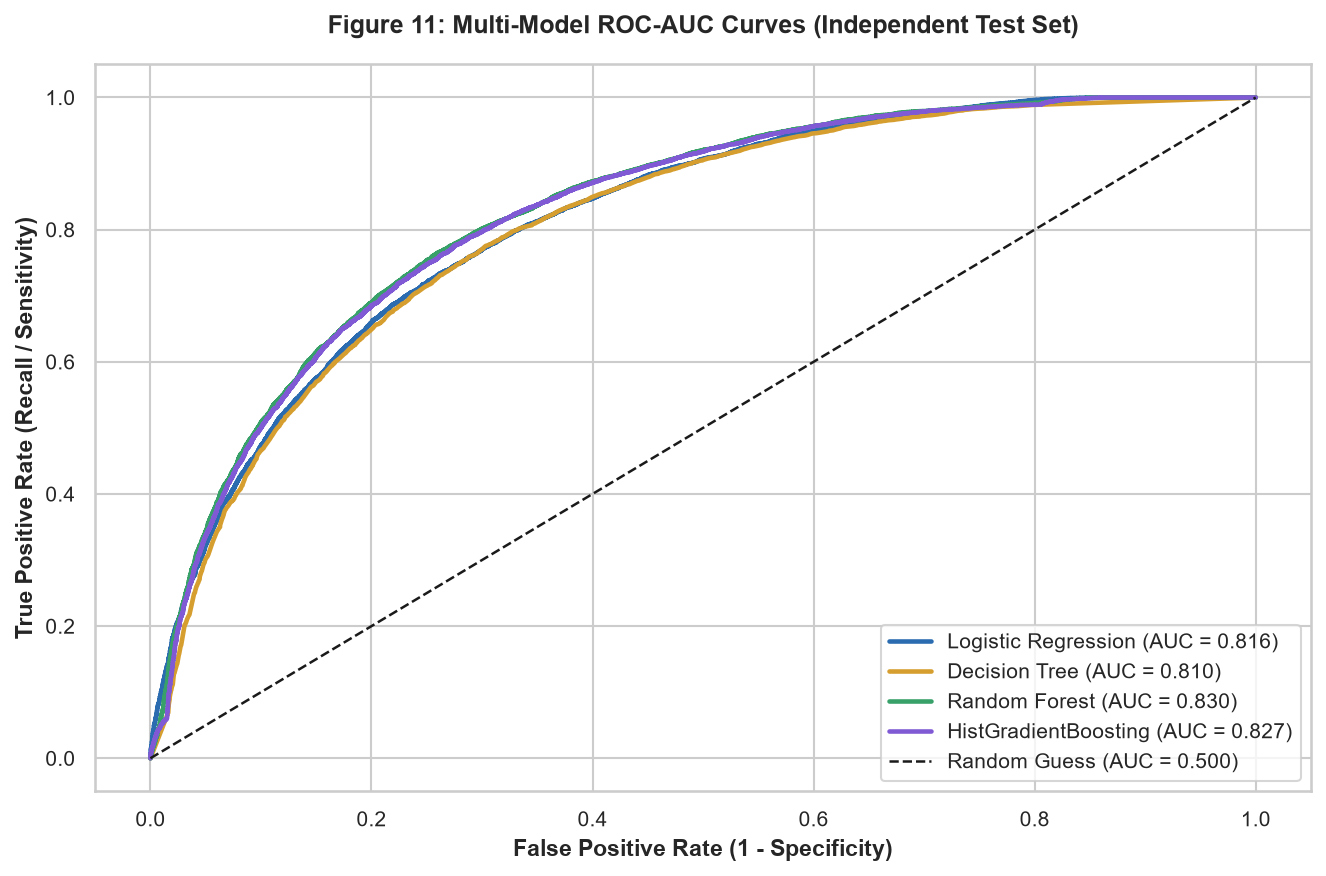

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))

colors = {
    "Logistic Regression": "#2b6cb0", 
    "Decision Tree": "#d69e2e", 
    "Random Forest": "#38a169",
    "HistGradientBoosting": "#805ad5"
}

for name in models.keys():
    proba = predictions_dict[name]["proba"]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors[name], linewidth=2.2)

ax.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.500)", linewidth=1.2)
ax.set_title("Figure 11: Multi-Model ROC-AUC Curves (Independent Test Set)", pad=15)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontweight="bold")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontweight="bold")
ax.legend(loc="lower right", fontsize=10)

plt.tight_layout()
save_figure(fig, "11_reorder_roc_curves.png")
plt.show()

### Precision-Recall Curves

[Exported Figure] -> reports\figures\12_reorder_precision_recall_curves.png


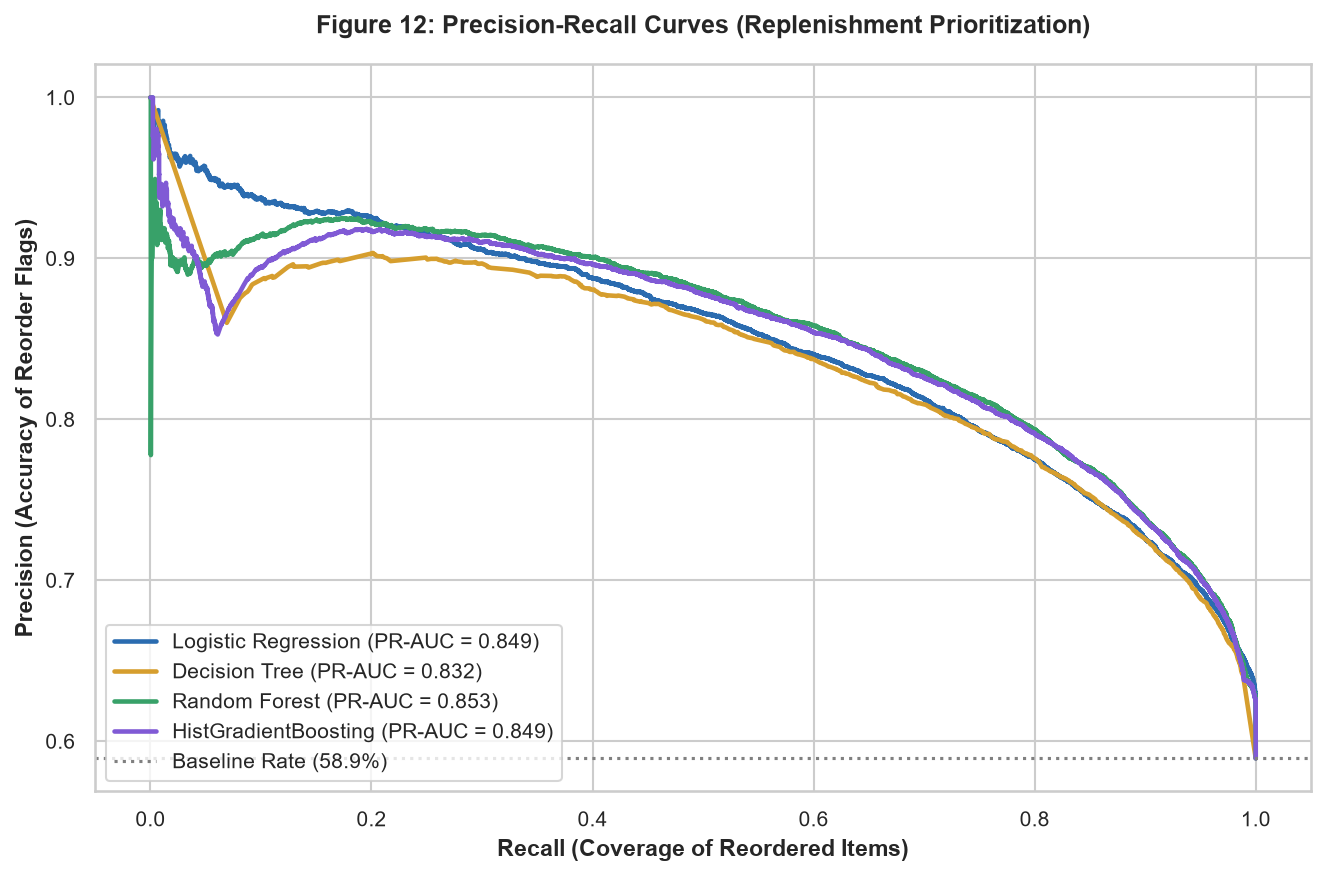

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))

for name in models.keys():
    proba = predictions_dict[name]["proba"]
    prec, rec, _ = precision_recall_curve(y_test, proba)
    pr_auc = average_precision_score(y_test, proba)
    ax.plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.3f})", color=colors[name], linewidth=2.2)

baseline_reorder_rate = y_test.mean()
ax.axhline(baseline_reorder_rate, color="gray", linestyle=":", label=f"Baseline Rate ({baseline_reorder_rate*100:.1f}%)")
ax.set_title("Figure 12: Precision-Recall Curves (Replenishment Prioritization)", pad=15)
ax.set_xlabel("Recall (Coverage of Reordered Items)", fontweight="bold")
ax.set_ylabel("Precision (Accuracy of Reorder Flags)", fontweight="bold")
ax.legend(loc="lower left", fontsize=10)

plt.tight_layout()
save_figure(fig, "12_reorder_precision_recall_curves.png")
plt.show()

### 4-Way Confusion Matrix Comparison

[Exported Figure] -> reports\figures\13_reorder_confusion_matrix.png


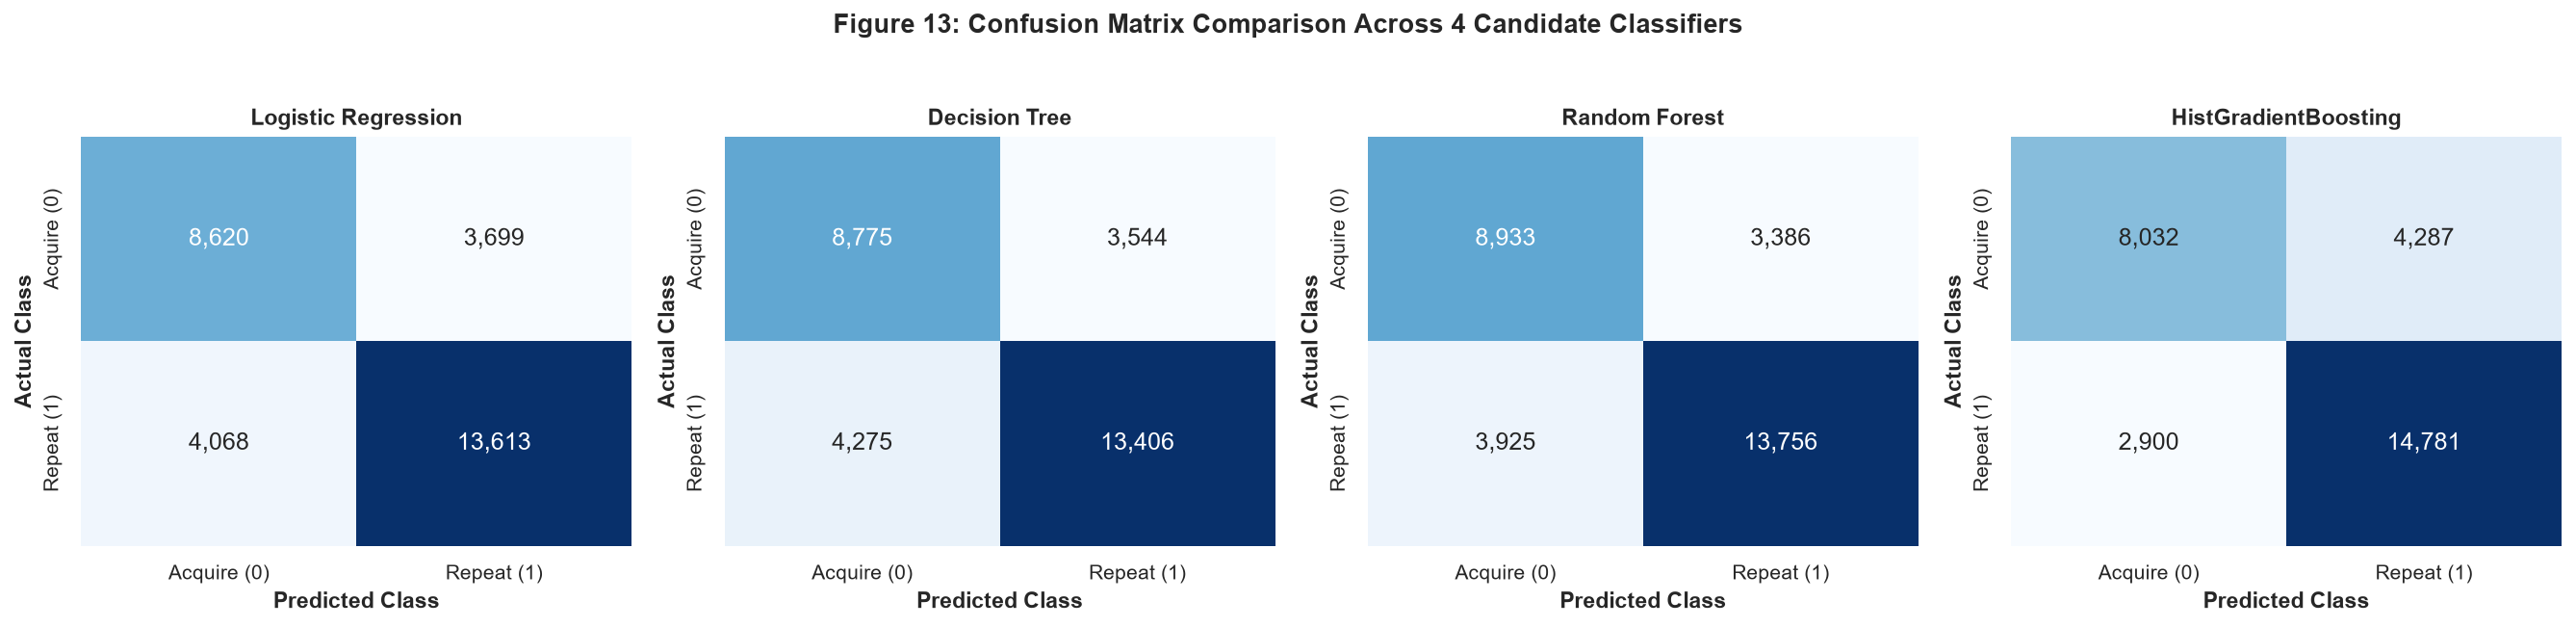

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for ax, name in zip(axes, models.keys()):
    pred = predictions_dict[name]["pred"]
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
        xticklabels=["Acquire (0)", "Repeat (1)"],
        yticklabels=["Acquire (0)", "Repeat (1)"],
        ax=ax
    )
    ax.set_title(f"{name}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Predicted Class", fontweight="bold")
    ax.set_ylabel("Actual Class", fontweight="bold")

fig.suptitle("Figure 13: Confusion Matrix Comparison Across 4 Candidate Classifiers", y=1.03, fontsize=13, fontweight="bold")
plt.tight_layout()
save_figure(fig, "13_reorder_confusion_matrix.png")
plt.show()

## 4. Operational Cost Trade-Off Assessment & Champion Selection
In retail inventory management, prediction errors have asymmetric costs:
* **False Positive (Type I Error)**: Flagging an item for reorder when not needed $\rightarrow$ slight inventory holding cost (Rs. 30/unit).
* **False Negative (Type II Error)**: Missing a reorder when due $\rightarrow$ **stockout, lost sales revenue, and dissatisfied shoppers** (Rs. 150/unit).  
We quantify total inventory risk to select the champion model.

In [26]:
holding_cost = 30.0   # Rs. 30 per unit holding waste
stockout_cost = 150.0 # Rs. 150 per stockout lost gross margin

trade_off_rows = []
for name in models.keys():
    pred = predictions_dict[name]["pred"]
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    
    total_loss = (fn * stockout_cost) + (fp * holding_cost)
    trade_off_rows.append({
        "Model": name,
        "False Negatives (Stockouts)": fn,
        "False Positives (Excess Holding)": fp,
        "Financial Risk Index (Rs.)": round(total_loss, 2)
    })

df_tradeoff = pd.DataFrame(trade_off_rows).sort_values(by="Financial Risk Index (Rs.)").reset_index(drop=True)
export_summary_table(df_tradeoff, "inventory_financial_risk_tradeoff.csv")
display(df_tradeoff)

[Exported Table]  -> reports\tables\inventory_financial_risk_tradeoff.csv


,Model,False Negatives (Stockouts),False Positives (Excess Holding),Financial Risk Index (Rs.)
0,HistGradientBoosting,2900,4287,563610.0
1,Random Forest,3925,3386,690330.0
2,Logistic Regression,4068,3699,721170.0
3,Decision Tree,4275,3544,747570.0


In [27]:
champion_name = df_tradeoff.iloc[0]["Model"]
champion_model = models[champion_name]

champion_path = MODELS_DIR / "champion_reorder_model.joblib"
joblib.dump(champion_model, champion_path)
print(f"\nCHAMPION MODEL SELECTED: {champion_name}")
print(f"Serialized champion model to: {champion_path}")


CHAMPION MODEL SELECTED: HistGradientBoosting
Serialized champion model to: E:\SLIIT\Y3S1\IT3091 - Machine Learning\Assignments\SuperMarket\supermarket-basket-reorder-analytics\models\champion_reorder_model.joblib


### Model Multi-Criteria Radar Comparison Chart

[Exported Figure] -> reports\figures\14_model_radar_comparison.png


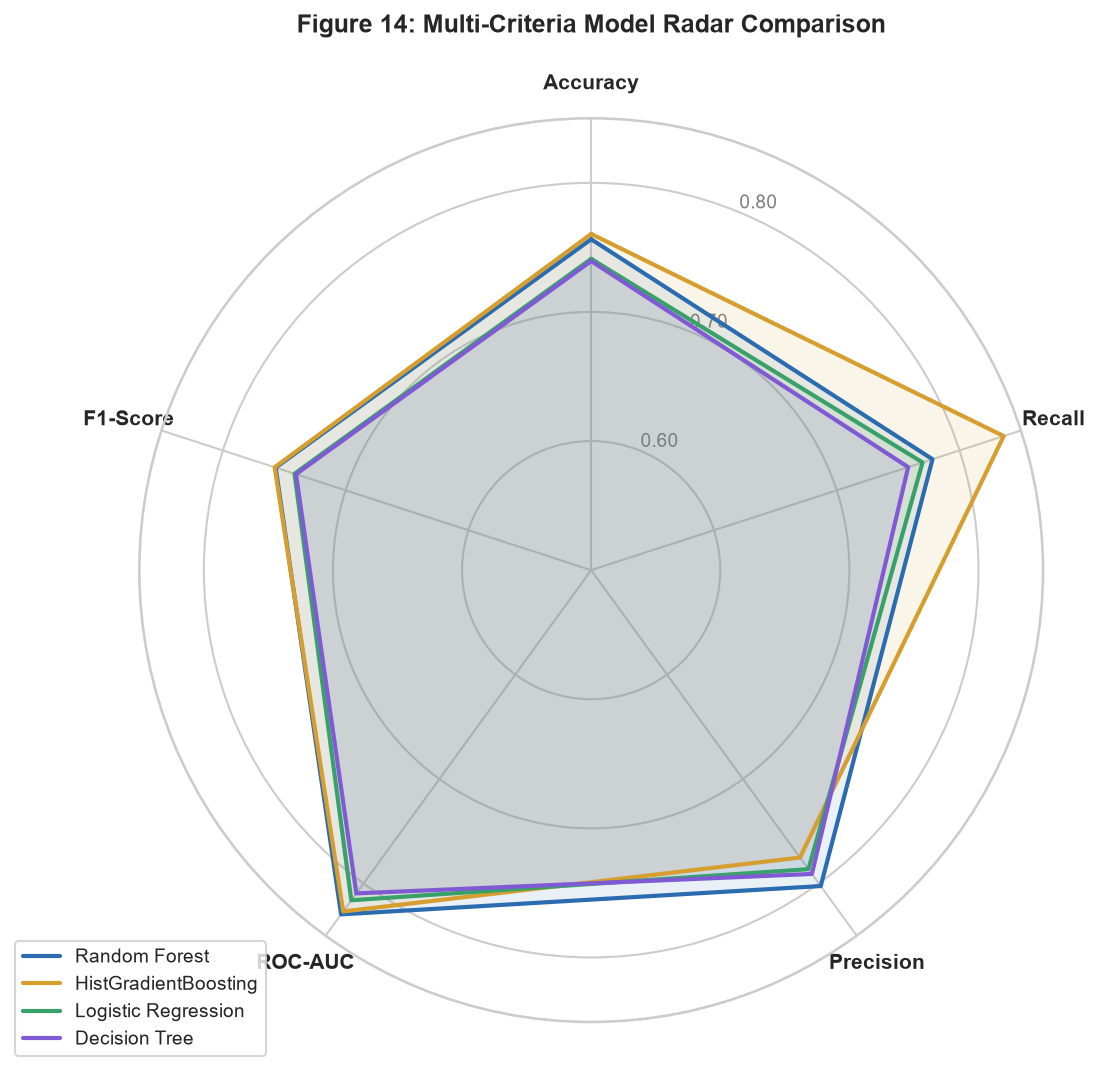

In [28]:
categories = ["Accuracy", "Recall", "Precision", "ROC-AUC", "F1-Score"]
N = len(categories)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw=dict(polar=True))
palette = ["#2b6cb0", "#d69e2e", "#38a169", "#805ad5"]

for idx, (_, row) in enumerate(df_benchmarks.iterrows()):
    values = [row["Accuracy"], row["Recall"], row["Precision"], row["ROC-AUC"], row["F1-Score (Weighted)"]]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle="solid", label=row["Model"], color=palette[idx])
    ax.fill(angles, values, color=palette[idx], alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], categories, fontweight="bold", fontsize=10)
plt.yticks([0.60, 0.70, 0.80], ["0.60", "0.70", "0.80"], color="grey", size=9)
plt.ylim(0.50, 0.85)

ax.set_title("Figure 14: Multi-Criteria Model Radar Comparison", pad=20, fontweight="bold")
ax.legend(loc="upper right", bbox_to_anchor=(0.15, 0.1), fontsize=9)

plt.tight_layout()
save_figure(fig, "14_model_radar_comparison.png")
plt.show()

## 5. Multi-Objective Evaluation of Association Rules
We ingest Obesekara's association rules from Notebook 02 and calculate a composite **Rule Quality Score**:
$$\text{Quality Score} = \text{Lift} \times \text{Confidence} \times \log_{10}(\text{Support} \times 10^5 + 1)$$
We prune low-conviction combinations to uncover the non-dominated Pareto frontier of actionable commercial bundles.

### Prune Rules & Figure 15 (Pareto Frontier)

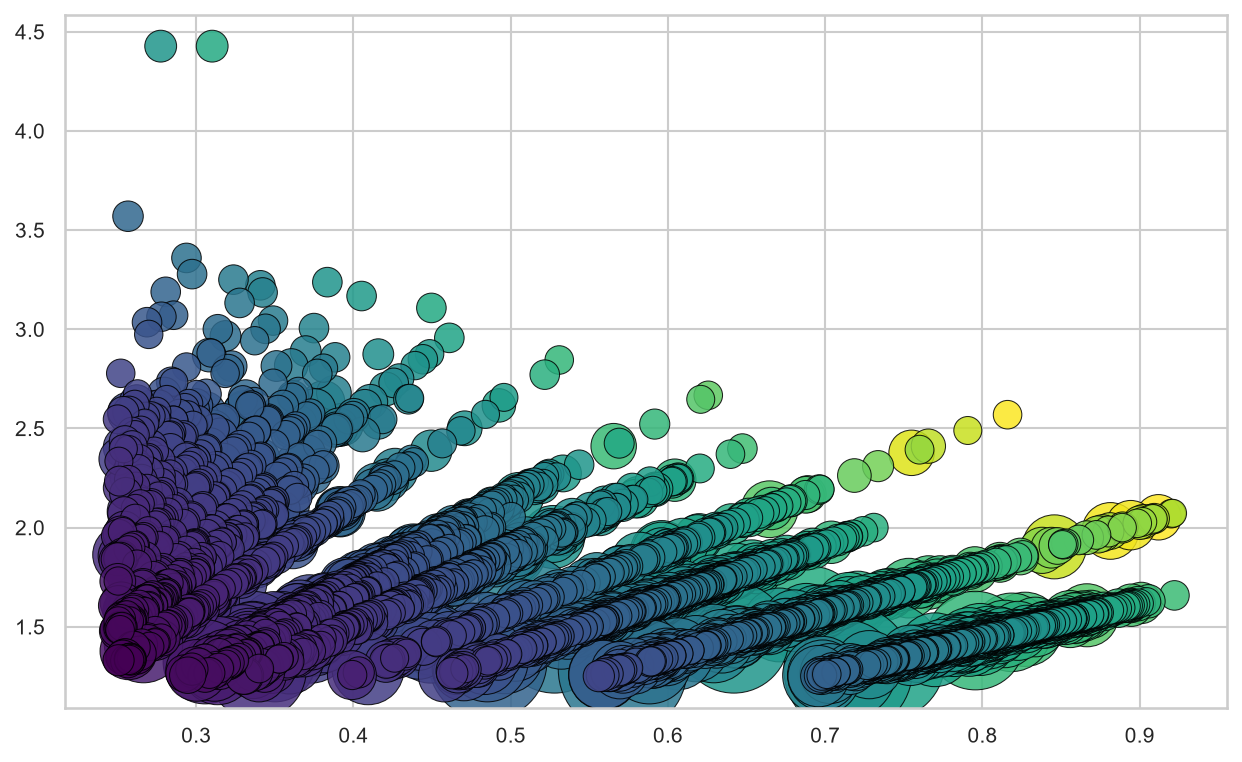

In [29]:
rules_df["quality_score"] = (
    rules_df["lift"] * rules_df["confidence"] * np.log10(rules_df["support"] * 100000 + 1)
).round(3)

pruned_rules = rules_df[
    (rules_df["lift"] >= 1.25) & 
    (rules_df["confidence"] >= 0.25) &
    (rules_df["conviction"] > 1.05)
].sort_values(by="quality_score", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    pruned_rules["confidence"], 
    pruned_rules["lift"],
    c=pruned_rules["quality_score"],
    cmap="viridis",
    s=pruned_rules["support"] * 12000,
    alpha=0.85,
    edgecolors="black",
    linewidth=0.5
)

In [30]:
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Composite Quality Score", fontweight="bold")
ax.set_title("Figure 15: Association Rule Quality Landscape (Confidence vs. Lift)", pad=15)
ax.set_xlabel("Rule Confidence (Predictive Reliability)", fontweight="bold")
ax.set_ylabel("Rule Lift (Statistical Affinity Multiplier)", fontweight="bold")

for i in range(min(3, len(pruned_rules))):
    r = pruned_rules.iloc[i]
    ax.annotate(
        f"{r['antecedents_str']} -> {r['consequents_str']}\n(Lift: {r['lift']:.2f}, Conf: {r['confidence']*100:.0f}%)",
        xy=(r["confidence"], r["lift"]),
        xytext=(r["confidence"] + 0.02, r["lift"] + 0.02),
        arrowprops=dict(arrowstyle="->", color="black"),
        fontsize=8.5,
        fontweight="medium"
    )

plt.tight_layout()
save_figure(fig, "15_association_rule_pareto_frontier.png")
plt.show()

C:\Users\sudha\AppData\Local\Temp\ipykernel_19168\1259159371.py:1: UserWarning: Adding colorbar to a different Figure <Figure size 1500x900 with 2 Axes> than <Figure size 960x720 with 0 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(scatter, ax=ax)


[Exported Figure] -> reports\figures\15_association_rule_pareto_frontier.png


<Figure size 960x720 with 0 Axes>

## 6. Sri Lankan Context Validation & Stakeholder Business Rulebooks
We cross-validate our findings against local Sri Lankan FMCG purchasing patterns and compile concrete operational rulebooks for our client, **Mr. M.K. Ajith**:
1. `reports/business_rules/store_layout_guide.md`
2. `reports/business_rules/restocking_priority_schedule.md`